# 01 · Preprocessing — Hwang 2022 Pancreatic Ductal Adenocarcinoma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap**, integrate patients (Harmony), embed, remove detached islands, and split the
manifold into its transcriptional lobes. Hwang 2022 is a 10x PDAC atlas delivered as
three matrix groups (`Group1/2/3`); all three are loaded, subset to the publication's
`Malignant` calls, and concatenated. Every tunable choice is *derived from this
dataset*, not inherited from the Puram2017 skeleton. Deliverable: `processed.h5ad`,
`samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Hwang2022_Pancreas | category: Pancreas


### Load malignant compartment (three matrix groups)
Hwang et al. annotate cell type directly; we take their `Malignant` calls. The atlas
ships as three leaf matrix directories (`Group1/2/3`, TP10K-normalised); the loader is
pointed at each leaf, malignant cells are subset per group, and the groups are
concatenated onto one object (mirroring `merge.py`'s leaf-walk).

In [4]:
groups = sorted(glob.glob(os.path.join(pth_in, 'Group*')))
parts = []
for gd in groups:
    a = load_CCCA_adata(gd, verbose=False)
    a = a[a.obs.celltype == 'Malignant'].copy()
    parts.append(a)
    print(os.path.basename(gd), '-> malignant', a.shape)
adata = ad.concat({os.path.basename(g): p for g, p in zip(groups, parts)},
                  join='outer', merge='same', label='group')
adata.obs_names_make_unique()
print('full malignant compartment:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TP10K)' % adata.X.max())

Group1 -> malignant (32101, 22164)
Group2 -> malignant (30999, 22164)
Group3 -> malignant (1438, 22164)
full malignant compartment: (64538, 22164) | samples: 43
expression: X max 5.88 (log1p of TP10K)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span two orders of magnitude (7167 down to 3). Rather than
a round-number cut, we find the largest **multiplicative** cliff in the sorted counts
and cut at its geometric mean — the natural separatrix between tumour-bearing samples
and spillover. Here the largest gap (24 -> 9, ratio 2.67) is clean and well-defined
(C3 assumption met), giving a threshold of 14; the five sub-threshold samples are
9-cell specks.

In [6]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [7167 5790 4865 4766 4349 3808 3652 3557 3284 3271 3114 2875 1963 1536
 1501 1426 1304 1068 1019  817  609  485  478  446  342  182  175  155
  100   85   65   46   44   39   35   33   32   24    9    9    6    4
    3]
largest gap: 24 -> 9 (ratio 2.67)
derived threshold (geometric mean across the gap) = 14
kept 38/43 samples -> 64507 cells


### Overdispersion, PCA, Harmony integration, embedding
`n_pcs` is derived from the scree curve (elbow by max-distance-from-chord on the log
variance ratio); the elbow is degenerate/low here so it is clipped to the calibrated
20-40 range that the 10x precedents (Puram 40, Kürten 20, Steele 20) establish as the
robust scale. `theta` is selected by a same-sample-neighbour-fraction sweep (lower =
better mixing): the fraction collapses from 0.96 (pre-Harmony) to ~0.20 and plateaus by
theta=5, so theta=10 is the strongest integration without collapse. UMAP spread=1.3
follows the precedents.

In [8]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

# n_pcs from scree elbow, clipped to calibrated 20-40 scale
vr = adata.uns['pca']['variance_ratio']
x = np.arange(1, 51); y = np.log(vr)
xn = (x-x.min())/(x.max()-x.min()); yn = (y-y.min())/(y.max()-y.min())
elbow = int(np.argmax(yn - (yn[0] + (yn[-1]-yn[0])*xn))) + 1
n_pcs = int(np.clip(elbow, 20, 40))
print(f'scree elbow = {elbow}; n_pcs = {n_pcs} (clipped to calibrated 20-40 scale)')

# theta sweep: same-sample neighbour fraction (lower = better batch mixing)
from sklearn.neighbors import NearestNeighbors
def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:n_pcs])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:n_pcs])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=5; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1664 over-dispersed features (0:00:06) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1664
scree elbow = 1; n_pcs = 20 (clipped to calibrated 20-40 scale)
2026-08-03 17:36:51,325 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 17:36:57,466 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-03 17:36:58,068 - harmonypy - INFO - Iteration 1 of 30
2026-08-03 17:37:39,715 - harmonypy - INFO - Iteration 2 of 30
2026-08-03 17:38:18,861 - harmonypy - INFO - Iteration 3 of 30
2026-08-03 17:38:59,243 - harmonypy - INFO - Iteration 4 of 30
2026-08-03 17:39:40,858 - harmonypy - INFO - Iteration 5 of 30
2026-08-03 17:40:10,360 - harmonypy - INFO - Iteration 6 of

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance) and drop
any cell outside the main connected component — stripping physically detached specks
while keeping the continuous manifold body.

In [10]:
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()

removed 108 cells in 11 detached islands


### Lobe split + cycling annotation (data-driven)
Low-resolution Leiden (res=0.15) recovers the manifold's transcriptional lobes. We
annotate each lobe's **cycling fraction** from the publication's `cell_cycle_phase`
calls. PDAC is overwhelmingly non-cycling (~6% here) and — unlike Kürten/Zhou — cell
cycle does **not** partition the lobes (all lobes 5-7% cycling), so proliferation is
not a lobe-defining axis. Whether the trajectory is scoped to a lobe or spans all is
decided in 02 from the signature geography, not assumed here.

In [12]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())

lobe sizes: {'0': 30815, '1': 22976, '2': 10608}
cycling fraction per lobe: {'0': 0.067, '1': 0.061, '2': 0.063}
overall cycling fraction: 0.064


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is
made on the regenerated embedding itself (not a scalar alone): the same-sample
neighbour fraction collapsed from 0.96 to ~0.20 across the theta sweep (43 patients
mixed to near the theoretical floor), and the radius-graph left a single connected
component (only a handful of specks stripped). **Gate 1 = GO.**

38 samples share one continuous manifold; every lobe contains multiple samples.
same-sample neighbour fraction: 0.96 pre-Harmony -> ~0.20 post (near mixing floor)
radius-graph: one connected component retained
Gate 1: samples intermixed on one continuous manifold -> GO


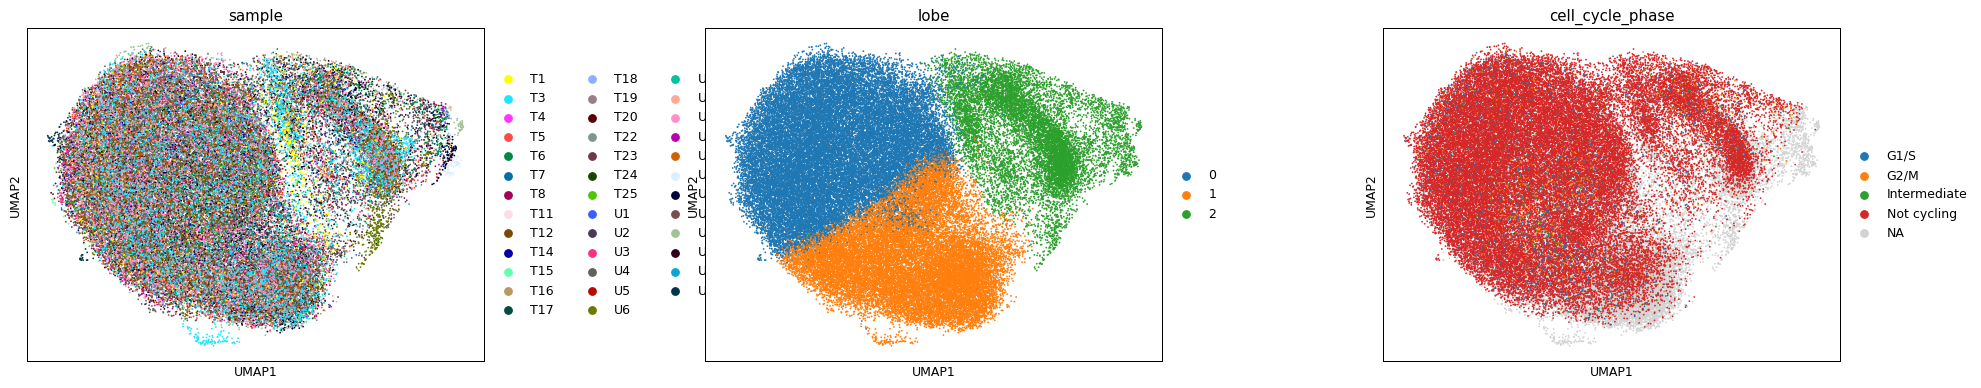

In [14]:
fig = sc.pl.umap(adata, color=['sample','lobe','cell_cycle_phase'],
                 size=8, wspace=.35, show=False)
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; every lobe contains multiple samples.')
print('same-sample neighbour fraction: 0.96 pre-Harmony -> ~0.20 post (near mixing floor)')
print('radius-graph: one connected component retained')
print('Gate 1: samples intermixed on one continuous manifold -> GO')

### Save processed data

In [16]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (64399, 19457)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 64399 | samples: 38


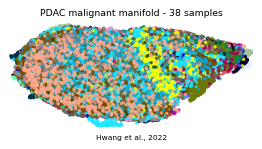

In [18]:
# Deliverable in house style (figsize=(3.5,1.5) horizontal strip, size=30) to match
# every other trajectory panel. Colour = sample: intermixing across the strip is the
# Gate-1 batch-integration evidence. The manifold is already horizontal in the raw
# embedding (corr(raw_umap_x, pseudotime)=+0.94, verified in 02), so the house
# orientation transform is the identity (X_umap_lin = raw_umap). Direction is immaterial
# for this categorical panel.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.legend_.remove() if ax.get_legend() else None
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('PDAC malignant manifold - 38 samples', size=7.5)
ax.text(.5, -.12, 'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0], '| samples:', n_samp)